# Case Study 11 — Which Customers Are About to Churn?

**Logistic regression · probability, odds and log-odds · odds ratios vs risk ratios · likelihood-ratio tests ·
non-linear effects with splines · interactions · separation · average marginal effects in percentage points ·
calibration and discrimination · expected-value thresholds under a capacity limit**

| | |
|---|---|
| **Domain** | Retail banking: savings-account retention |
| **Stakeholders** | Head of Retail Liabilities, Retention team lead |
| **Difficulty** | Intermediate |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Case 02 (two-group tests, odds ratios), Case 07 (multiple regression) |
| **Data** | 12,000 savings customers; churn measured over the next 6 months |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. Why ordinary regression is the wrong tool for a yes/no outcome, and what logistic regression does instead.
2. How to move between **probability, odds and log-odds**, and how to explain an **odds ratio** without saying
   "times more likely" when you mean something else.
3. How to test groups of variables, non-linear effects and interactions with **likelihood-ratio tests**.
4. How to turn the model into **percentage-point** effects and into a **call list** that maximises value.

## Section 1 — Business context

You are a data scientist in the bank's **Retail Liabilities** analytics team. About one in ten savings customers
closes their account or moves most of their money out within six months. Each lost customer is worth about **₹12,000**
over three years. The retention team can offer a fee waiver plus cashback (cost about **₹600** per customer contacted),
and it can make about **1,000 calls** for this cohort.

The Head of Retail Liabilities writes:

> *"The dashboard says customers with complaints are three times more likely to leave. Is that right? What really
> drives churn, and how much does each factor matter in plain terms? Most importantly: whom should we call, and is the
> offer even worth making?"*

## Section 2 — Business questions

1. What drives churn, holding the other factors fixed?
2. Is "complaints make customers three times more likely to leave" correct?
3. How much does each factor change the **probability** of churn, in percentage points?
4. Whom should the retention team call (1,000 calls), and at what churn probability does the offer pay for itself?
5. Can we trust the model's probabilities?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Drivers | Conditional association of each variable with the log-odds of churn | Multiple logistic regression; Wald and likelihood-ratio tests |
| 2 | "Three times more likely" | Odds ratio vs risk ratio for complaints | 2×2 table; logistic coefficients |
| 3 | Effects in plain terms | Change in predicted probability | Average marginal effects (percentage points) |
| 4 | Whom to call | Rank by predicted probability; expected-value threshold under a capacity limit | Out-of-fold predictions, gains chart, expected value |
| 5 | Trust the probabilities | Discrimination and calibration on unseen customers | AUC, calibration plot, Hosmer-Lemeshow, Brier score |

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.model_selection import StratifiedKFold

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from statistical_tests import proportion_ci
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "11_churn_logistic_regression"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(1111)
pctfmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}".replace("-", "−"))

CLV, OFFER_COST, OFFER_SUCCESS, CAPACITY = 12_000, 600, 0.35, 1_000

def wilson(k, n):
    ci = proportion_ci(int(k), int(n))
    return ci["lower"], ci["upper"]

def lr_test(small, big):
    # Likelihood-ratio test for nested logistic models.
    stat = 2 * (big.llf - small.llf)
    dof = int(big.df_model - small.df_model)
    return {"LR χ²": stat, "df": dof, "p_value": stats.chi2.sf(stat, dof)}

## Section 4 — Load the data

In [2]:
cust = pd.read_csv(PATHS["data"] / "savings_customers.csv", dtype={"complaints_6m": str})
print(f"{cust.shape[0]:,} customers × {cust.shape[1]} columns;  duplicates: {cust['customer_id'].duplicated().sum()};  "
      f"missing: {cust.isna().sum().sum()}")
display(cust.head())
pd.DataFrame({"type": ["numeric", "numeric", "ordinal (3) + NRI", "nominal (5)", "count (1–4)", "binary", "binary",
                       "count", "numeric (%)", "ordinal (0 / 1 / 2+)", "binary TARGET"]}, index=cust.columns[1:])

12,000 customers × 12 columns;  duplicates: 0;  missing: 0


,customer_id,age,tenure_years,segment,region,num_products,salary_account,has_credit_card,digital_logins_per_month,balance_change_3m_pct,complaints_6m,churned_6m
0,SB11100000,39,3.7000,Mass,North,1,0,0,7,6.2000,2+,1
1,SB11100001,26,6.4000,Affluent,North,2,0,0,14,13.1000,0,0
2,SB11100002,51,1.0000,Mass,South,2,0,0,14,14.3000,0,0
3,SB11100003,62,2.1000,Mass,South,1,0,0,3,24.0000,2+,0
4,SB11100004,56,6.5000,Affluent,South,2,0,1,8,-29.5000,0,0


,type
age,numeric
tenure_years,numeric
segment,ordinal (3) + NRI
region,nominal (5)
num_products,count (1–4)
salary_account,binary
has_credit_card,binary
digital_logins_per_month,count
balance_change_3m_pct,numeric (%)
complaints_6m,ordinal (0 / 1 / 2+)


In [3]:
cust["segment"] = pd.Categorical(cust["segment"], categories=["Mass", "Affluent", "Privileged", "NRI"])
cust["complaints_6m"] = pd.Categorical(cust["complaints_6m"], categories=["0", "1", "2+"])
cust["region"] = pd.Categorical(cust["region"], categories=["North", "South", "East", "West", "Central"])
base_rate = cust["churned_6m"].mean()
lo, hi = wilson(cust["churned_6m"].sum(), len(cust))
print(f"Churn rate over 6 months: {base_rate:.1%}  (95% CI {lo:.1%} to {hi:.1%});  churners: {cust['churned_6m'].sum():,}")

Churn rate over 6 months: 10.5%  (95% CI 9.9% to 11.0%);  churners: 1,255

## Section 5 — Descriptive statistics

In [4]:
rows = []
for col in ["complaints_6m", "segment", "num_products", "salary_account", "has_credit_card", "region"]:
    for lvl, g in cust.groupby(col, observed=True):
        k, n = g["churned_6m"].sum(), len(g)
        l, h = wilson(k, n)
        rows.append({"variable": col, "level": str(lvl), "customers": n, "churners": k, "churn rate": k / n,
                     "ci_low": l, "ci_high": h})
cat_tbl = pd.DataFrame(rows).set_index(["variable", "level"])
save_table(cat_tbl, "churn_by_category", PATHS["tables"])
display(cat_tbl)
num_tbl = cust.groupby("churned_6m")[["age", "tenure_years", "digital_logins_per_month", "balance_change_3m_pct"]].median().T
num_tbl.columns = ["median: stayed", "median: churned"]
num_tbl

customers  churners  churn rate  ci_low  ci_high
variable        level                                                       
complaints_6m   0               10182       894      0.0878  0.0825   0.0935
                1                1347       226      0.1678  0.1488   0.1887
                2+                471       135      0.2866  0.2476   0.3291
segment         Mass             8397       942      0.1122  0.1056   0.1191
                Affluent         2933       274      0.0934  0.0834   0.1045
                Privileged        612        39      0.0637  0.0470   0.0859
                NRI                58         0      0.0000  0.0000   0.0621
num_products    1                4840       681      0.1407  0.1312   0.1508
                2                4208       404      0.0960  0.0875   0.1053
                3                1972       122      0.0619  0.0521   0.0734
                4                 980        48      0.0490  0.0371   0.0643
salary_account  0                6618       933      0.1410  0.1328   0.1496
                1                5382       322      0.0598  0.0538   0.0665
has_credit_card 0                7755       895      0.1154  0.1085   0.1227
                1                4245       360      0.0848  0.0768   0.0936
region          North            3025       310      0.1025  0.0922   0.1138
                South            3036       317      0.1044  0.0940   0.1158
                East             1840       191      0.1038  0.0907   0.1186
                West             2565       273      0.1064  0.0951   0.1190
                Central          1534       164      0.1069  0.0924   0.1234

,median: stayed,median: churned
age,40.0000,39.0000
tenure_years,3.3000,2.2000
digital_logins_per_month,9.0000,8.0000
balance_change_3m_pct,2.5000,-8.1000


**Observation.** Churn is about **10.5%** overall. It is higher for customers with complaints (≈ 17% with one, ≈ 29%
with two or more, against ≈ 9% with none), lower for customers with more products, a salary account or a credit card,
and similar across regions. Churners are newer, slightly younger, log in slightly less, and their balances have been falling. **None
of the 58 NRI customers churned.**

**Caveat.** Each of these comparisons is one variable at a time. Customers with complaints may also differ in tenure,
products or salary accounts (Case 08), so we need a model that holds the others fixed.

## Section 6 — Visualisation

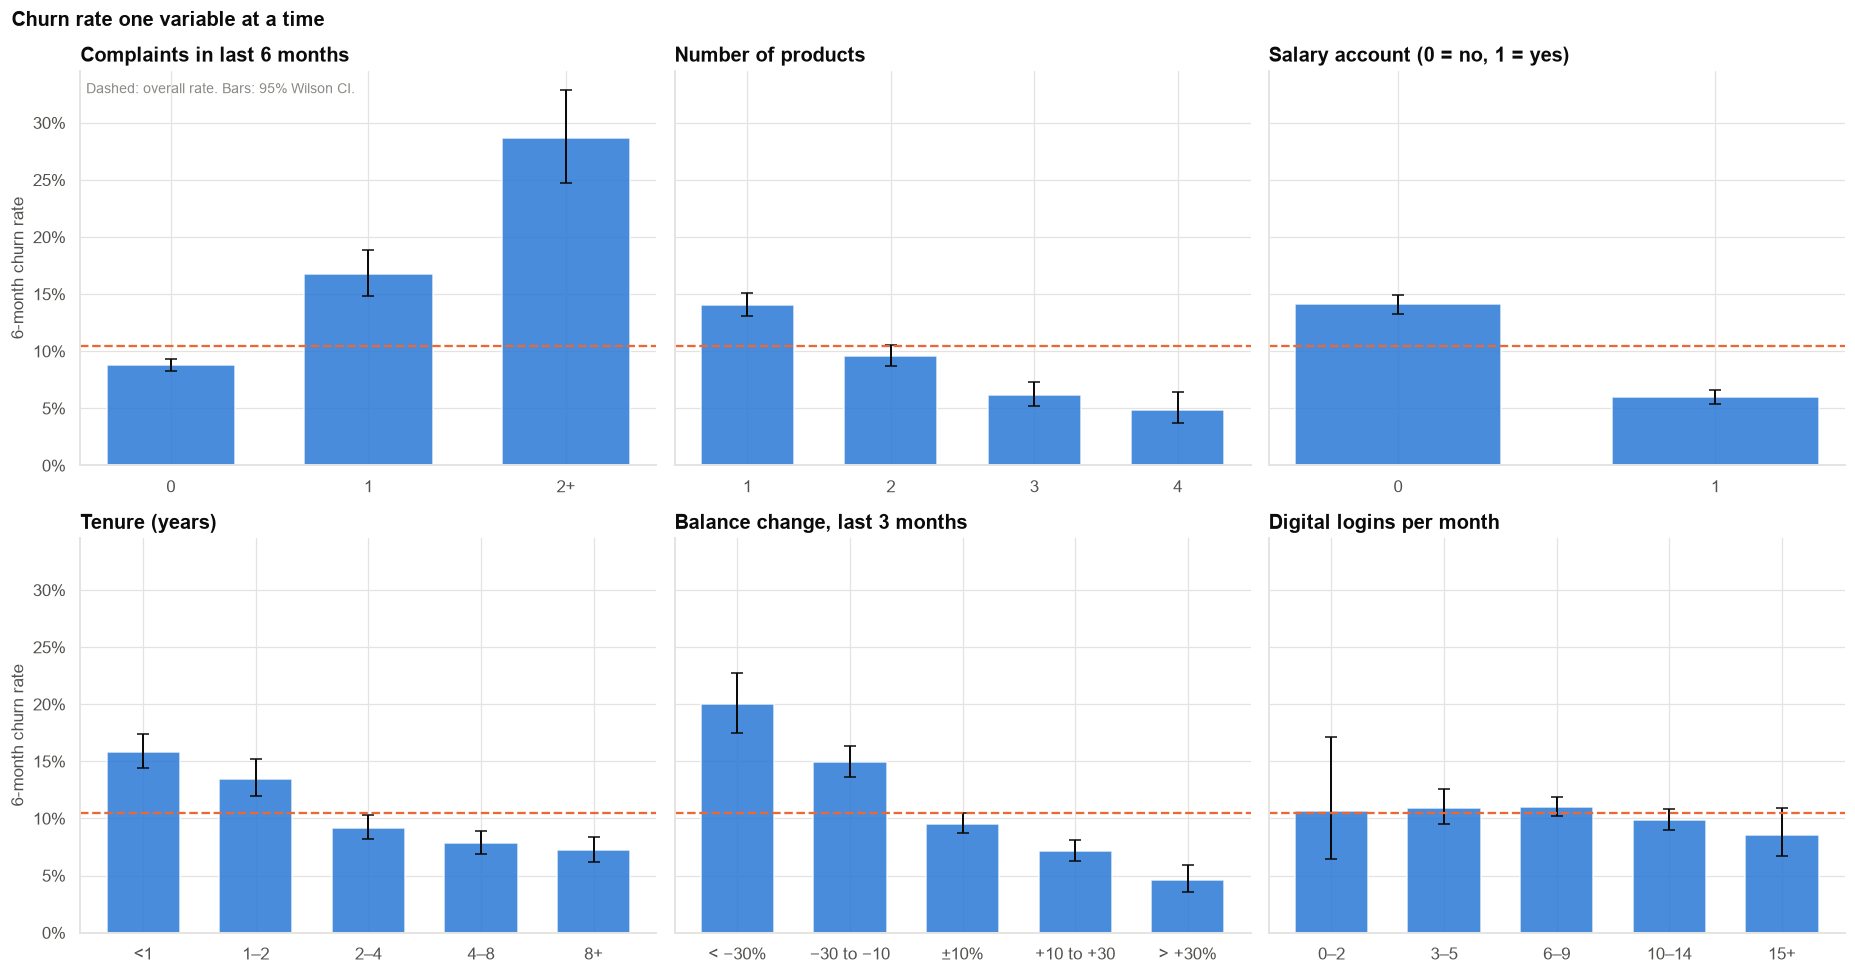

In [5]:
plot_df = cust.assign(
    tenure_band=pd.cut(cust["tenure_years"], [-0.1, 1, 2, 4, 8, 50], labels=["<1", "1–2", "2–4", "4–8", "8+"]),
    balance_band=pd.cut(cust["balance_change_3m_pct"], [-101, -30, -10, 10, 30, 200], labels=["< −30%", "−30 to −10", "±10%", "+10 to +30", "> +30%"]),
    login_band=pd.cut(cust["digital_logins_per_month"], [-1, 2, 5, 9, 14, 100], labels=["0–2", "3–5", "6–9", "10–14", "15+"]))
panels = [("complaints_6m", "Complaints in last 6 months"), ("num_products", "Number of products"),
          ("salary_account", "Salary account (0 = no, 1 = yes)"), ("tenure_band", "Tenure (years)"),
          ("balance_band", "Balance change, last 3 months"), ("login_band", "Digital logins per month")]
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharey=True)
for ax, (col, lab) in zip(axes.flat, panels):
    g = plot_df.groupby(col, observed=True)["churned_6m"].agg(["sum", "size"])
    rates = g["sum"] / g["size"]
    cis = np.array([wilson(k, n) for k, n in zip(g["sum"], g["size"])])
    x = np.arange(len(g))
    ax.bar(x, rates, color=PRIMARY, alpha=0.85, width=0.65)
    ax.errorbar(x, rates, yerr=[rates - cis[:, 0], cis[:, 1] - rates], fmt="none", color=INK, capsize=4, lw=1.3)
    ax.axhline(base_rate, color=HIGHLIGHT, ls="--", lw=1.5)
    ax.set_xticks(x, [str(v) for v in g.index])
    ax.yaxis.set_major_formatter(pctfmt)
    ax.set(title=lab, ylabel="6-month churn rate" if ax in axes[:, 0] else "")
add_note(axes[0, 0], "Dashed: overall rate. Bars: 95% Wilson CI.", "upper left")
fig.suptitle("Churn rate one variable at a time", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig01_churn_by_variable", PATHS["figures"])
plt.show()

**Observation.** The clearest one-variable patterns: complaints (strongly up), products and salary accounts (down),
tenure (customers in their **first year** churn much more, then the rate flattens: a non-linear pattern) and falling
balances (strongly up). Digital logins look almost **flat** on their own. Keep an eye on that: younger customers log
in more **and** churn more, so the two effects cancel in the raw chart (masking, Case 08). The model will separate
them.

## Section 7 — Method selection: why logistic regression?

### 7.1 Why not ordinary regression on a 0/1 outcome?

A **linear probability model** (OLS on churn = 0/1) is quick, but it can predict "probabilities" below 0 or above 1,
its errors cannot have constant variance, and it forces every effect to be the same number of percentage points for
everyone.

Linear probability model (all variables): 1,148 customers get a 'probability' outside 0–1 (min -0.20, max 0.46)


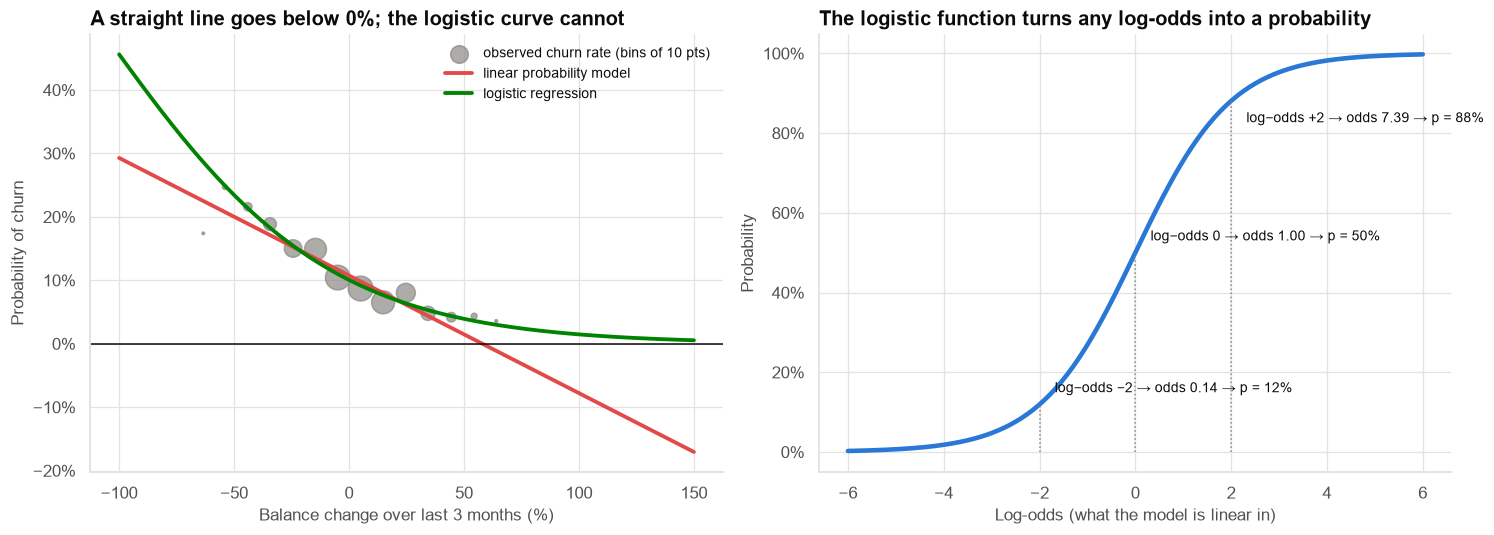

In [6]:
F_SIMPLE = "churned_6m ~ balance_change_3m_pct"
lpm = smf.ols("churned_6m ~ age + tenure_years + num_products + salary_account + has_credit_card + digital_logins_per_month"
              " + balance_change_3m_pct + complaints_6m + segment + region", cust).fit()
print(f"Linear probability model (all variables): {((lpm.fittedvalues < 0) | (lpm.fittedvalues > 1)).sum():,} customers get a "
      f"'probability' outside 0–1 (min {lpm.fittedvalues.min():.2f}, max {lpm.fittedvalues.max():.2f})")
lpm1, logit1 = smf.ols(F_SIMPLE, cust).fit(), smf.logit(F_SIMPLE, cust).fit(disp=0)
xs = pd.DataFrame({"balance_change_3m_pct": np.linspace(-100, 150, 200)})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
band = pd.cut(cust["balance_change_3m_pct"], np.arange(-100, 160, 10))
emp = cust.groupby(band, observed=True).agg(x=("balance_change_3m_pct", "mean"), y=("churned_6m", "mean"), n=("churned_6m", "size"))
emp = emp[emp["n"] >= 20]
ax.scatter(emp["x"], emp["y"], s=emp["n"] / 8, color=INK_MUTED, alpha=0.7, label="observed churn rate (bins of 10 pts)")
ax.plot(xs["balance_change_3m_pct"], lpm1.predict(xs), color=COLORS["red"], lw=2.5, label="linear probability model")
ax.plot(xs["balance_change_3m_pct"], logit1.predict(xs), color=COLORS["green"], lw=2.5, label="logistic regression")
ax.axhline(0, color=INK, lw=1)
ax.yaxis.set_major_formatter(pctfmt)
ax.set(xlabel="Balance change over last 3 months (%)", ylabel="Probability of churn",
       title="A straight line goes below 0%; the logistic curve cannot")
ax.legend(frameon=False, fontsize=9)
ax = axes[1]
z = np.linspace(-6, 6, 200)
ax.plot(z, 1 / (1 + np.exp(-z)), color=PRIMARY, lw=3)
for zz in [-2, 0, 2]:
    pz = 1 / (1 + np.exp(-zz))
    ax.plot([zz, zz], [0, pz], color=INK_MUTED, ls=":", lw=1)
    ax.annotate(f"log-odds {zz:+d} → odds {np.exp(zz):.2f} → p = {pz:.0%}".replace("-", "−").replace("+0", "0"), (zz, pz), xytext=(10, -14 if zz > 0 else 8),
                textcoords="offset points", fontsize=9)
ax.yaxis.set_major_formatter(pctfmt)
ax.set(xlabel="Log-odds (what the model is linear in)", ylabel="Probability",
       title="The logistic function turns any log-odds into a probability")
fig.tight_layout()
save_fig(fig, "fig02_lpm_vs_logistic", PATHS["figures"])
plt.show()

**Observation.** The linear probability model gives over a thousand customers impossible "probabilities" (many below
zero). The logistic curve follows the observed rates and stays between 0 and 1.

### 7.2 Probability, odds and log-odds

Logistic regression is a **linear model for the log-odds**:

  log( p / (1 − p) ) = β₀ + β₁x₁ + … + βₖxₖ

| Quantity | Formula | 10% churn | 25% churn | 50% churn |
|---|---|---|---|---|
| Probability p | – | 0.10 | 0.25 | 0.50 |
| Odds | p / (1 − p) | 0.11 ("1 to 9") | 0.33 ("1 to 3") | 1.00 ("1 to 1") |
| Log-odds | log(odds) | −2.20 | −1.10 | 0 |

- A coefficient β is the change in **log-odds** for a one-unit change in x, holding the others fixed.
- **e^β is an odds ratio**: the factor by which the **odds** are multiplied.
- The change in **probability** depends on where you start (Section 12).

| Candidate | Verdict |
|---|---|
| Linear probability model | ❌ Impossible predictions, constant pp effects; OK only as a quick approximation near the middle |
| **Logistic regression** | ✅ Valid probabilities, interpretable odds ratios, standard tests (Wald, likelihood ratio) |
| Probit | ≈ Same fit; coefficients less interpretable |
| Tree-based ML | ❌ Not needed for drivers; see Case 13 for when it is worth it |

## Section 8 — Is "three times more likely" right? Odds ratios vs risk ratios

In [7]:
cust["any_complaint"] = (cust["complaints_6m"] != "0").astype(int)
tab = pd.crosstab(cust["any_complaint"], cust["churned_6m"])
a, b = tab.loc[1, 1], tab.loc[1, 0]        # complaint: churned, stayed
c, d = tab.loc[0, 1], tab.loc[0, 0]        # no complaint: churned, stayed
p1, p0 = a / (a + b), c / (c + d)
or_hand = (a / b) / (c / d)
m_or = smf.logit("churned_6m ~ any_complaint", cust).fit(disp=0)
rr = p1 / p0
two = pd.DataFrame({"value": [p0, p1, p1 - p0, rr, or_hand, np.exp(m_or.params["any_complaint"])]},
                   index=["churn rate, no complaint", "churn rate, any complaint", "risk difference (pp)", "risk ratio",
                          "odds ratio (from the 2×2 table)", "odds ratio (e^β from logistic regression)"])
save_table(two, "complaint_2x2", PATHS["tables"])
display(tab.rename(index={0: "no complaint", 1: "any complaint"}, columns={0: "stayed", 1: "churned"}))
display(two)
g2 = cust[cust["complaints_6m"] == "2+"]["churned_6m"].mean()
print(f"2+ complaints vs none: risk ratio {g2 / p0:.2f}, odds ratio {(g2 / (1 - g2)) / (p0 / (1 - p0)):.2f}")

conv = pd.DataFrame({"baseline risk": [0.02, 0.10, 0.25, 0.50]})
for orv in [2, 3, 5]:
    po = conv["baseline risk"] / (1 - conv["baseline risk"]) * orv
    conv[f"OR = {orv}: risk ratio"] = (po / (1 + po)) / conv["baseline risk"]
save_table(conv.set_index("baseline risk"), "or_to_rr_conversion", PATHS["tables"])
conv.set_index("baseline risk")

churned_6m,stayed,churned
any_complaint,,
no complaint,9288,894
any complaint,1457,361


,value
"churn rate, no complaint",0.0878
"churn rate, any complaint",0.1986
risk difference (pp),0.1108
risk ratio,2.2616
odds ratio (from the 2×2 table),2.5741
odds ratio (e^β from logistic regression),2.5741


2+ complaints vs none: risk ratio 3.26, odds ratio 4.17


,OR = 2: risk ratio,OR = 3: risk ratio,OR = 5: risk ratio
baseline risk,,,
0.0200,1.9608,2.8846,4.6296
0.1000,1.8182,2.5000,3.5714
0.2500,1.6000,2.0000,2.5000
0.5000,1.3333,1.5000,1.6667


**Observation.** Customers with any complaint churn at about 20% against about 9% without: a **risk ratio** of about
2.3 and an **odds ratio** of about 2.6. The odds ratio from the 2×2 table equals e^β of a one-variable logistic
regression **exactly**. For **2+ complaints**, the risk ratio is about 3.3: the dashboard's "three times" is right for
that group, as a raw (unadjusted) comparison.

**Interpretation.**
- **Risk ratio** = ratio of probabilities ("times more likely"). **Odds ratio** = ratio of odds. They are close only
  when the outcome is **rare** (the table above: at 2% baseline risk, OR = 3 means RR ≈ 2.9; at 25%, RR = 2.0).
- Logistic regression gives **odds ratios**. Saying "OR = 3, so three times more likely" overstates the effect
  whenever churn is not rare.

**Caveat.** This is still a one-variable comparison. The adjusted effect comes in Section 12.

## Section 9 — Multiple logistic regression

### 9.1 First attempt: the NRI segment breaks the model (separation)

In [8]:
F_ALL = ("churned_6m ~ age + tenure_years + num_products + salary_account + has_credit_card + digital_logins_per_month"
         " + balance_change_3m_pct + complaints_6m + segment + region")
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    m_sep = smf.logit(F_ALL, cust).fit(disp=0, maxiter=200)
print("Warnings raised:", sorted({type(w.message).__name__ + ": " + str(w.message)[:70] for w in caught}))
print(f"NRI coefficient = {m_sep.params['segment[T.NRI]']:.1f}  (odds ratio {np.exp(m_sep.params['segment[T.NRI]']):.1e}), "
      f"SE = {m_sep.bse['segment[T.NRI]']:,.0f},  p = {m_sep.pvalues['segment[T.NRI]']:.2f}")
print(pd.crosstab(cust["segment"], cust["churned_6m"]))

Warnings raised: ['ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals']
NRI coefficient = -20.9  (odds ratio 8.3e-10), SE = 12,276,  p = 1.00
churned_6m     0    1
segment              
Mass        7455  942
Affluent    2659  274
Privileged   573   39
NRI           58    0


**Observation.** The fit fails to converge, and the NRI coefficient is absurd: about −20 on the log-odds scale with a
standard error in the thousands (so p ≈ 1).

**Interpretation: (quasi-)complete separation.** None of the 58 NRI customers churned. The likelihood keeps improving as
the NRI coefficient goes to −∞, so there is no finite maximum. The p-value near 1 does **not** mean "NRI has no
effect"; it means the estimate is broken.

**Remedies:**

| Remedy | When |
|---|---|
| Merge the level with a similar one | When a sensible neighbour exists |
| Remove the group from the model and handle it with a **business rule** | When the group is structurally different (NRI deposits are locked in) |
| **Penalised** (ridge) or **Firth** logistic regression | When you must keep every level; gives finite, shrunk estimates |
| Collect more data | When the group is important and the zero is chance |

NRI customers hold foreign-currency term deposits that make churn structurally rare, so we **exclude them from the
model** and treat them as very low risk by rule. We also show the penalised alternative.

In [9]:
# Ridge-penalised fit (L2) via a GLM with a small penalty on all coefficients except the intercept.
glm = smf.glm(F_ALL, cust, family=sm.families.Binomial())
alpha = np.full(len(m_sep.params), 0.5 / len(cust)); alpha[0] = 0.0
m_ridge = glm.fit_regularized(alpha=alpha, L1_wt=0.0, maxiter=500)
print(f"Ridge-penalised NRI coefficient: {m_ridge.params['segment[T.NRI]']:.2f} (odds ratio {np.exp(m_ridge.params['segment[T.NRI]']):.3f}): "
      f"finite and strongly negative")

model_df = cust[cust["segment"] != "NRI"].copy()
model_df["segment"] = model_df["segment"].cat.remove_unused_categories()
model_df["log_tenure"] = np.log1p(model_df["tenure_years"])
test_idx = rng.choice(model_df.index, size=3000, replace=False)
test, train = model_df.loc[test_idx].copy(), model_df.drop(index=test_idx).copy()
print(f"Modelling sample (NRI excluded): {len(model_df):,} → train {len(train):,} / test {len(test):,}")

Ridge-penalised NRI coefficient: -2.02 (odds ratio 0.133): finite and strongly negative
Modelling sample (NRI excluded): 11,942 → train 8,942 / test 3,000


### 9.2 The main-effects model

In [10]:
F_MAIN = ("churned_6m ~ age + tenure_years + num_products + salary_account + has_credit_card + digital_logins_per_month"
          " + balance_change_3m_pct + complaints_6m + segment + region")
m_main = smf.logit(F_MAIN, train).fit(disp=0)
m_noreg = smf.logit(F_MAIN.replace(" + region", ""), train).fit(disp=0)
m_noseg = smf.logit(F_MAIN.replace(" + segment", ""), train).fit(disp=0)
blocks = pd.DataFrame({"region (4 df)": lr_test(m_noreg, m_main), "segment (2 df)": lr_test(m_noseg, m_main)}).T
save_table(blocks, "lr_tests_blocks", PATHS["tables"])
display(blocks)
print(f"McFadden pseudo-R² = {m_main.prsquared:.3f};  log-likelihood {m_main.llf:,.1f} vs null {m_main.llnull:,.1f};  "
      f"LR test of the whole model: χ² = {m_main.llr:,.0f}, p = {fmt_p(m_main.llr_pvalue)}")

,LR χ²,df,p_value
region (4 df),0.5277,4.0000,0.9707
segment (2 df),2.6994,2.0000,0.2593


McFadden pseudo-R² = 0.109;  log-likelihood -2,678.6 vs null -3,006.2;  LR test of the whole model: χ² = 655, p = < 0.001


**Observation.** Region adds nothing (likelihood-ratio p ≈ 1), so we drop it. Segment is also not significant once
the other variables are in the model: Affluent and Privileged customers churn less only because they hold more
products and log in more (Case 08's confounding). We keep segment as a business-required control, but it carries no
weight in the story. The model as a whole is highly significant.

**Wald vs likelihood-ratio tests.** The p-values printed next to each coefficient are **Wald** tests (coefficient ÷
SE). For a **group** of dummies (region, segment), or when estimates are large, the **likelihood-ratio** test
(compare the fit with and without the group) is more reliable.

**About pseudo-R².** McFadden's R² of about 0.11 looks low, but values of 0.1–0.3 are typical for individual behaviour.
It is **not** "11% of variance explained". Judge the model by discrimination and calibration (Section 13).

## Section 10 — Non-linear effects: tenure

,AIC,LR test vs linear
tenure linear,"5,381.6392",NaN
log(1 + tenure),"5,348.8213",NaN
spline in tenure (4 df),"5,332.4423",0.0000


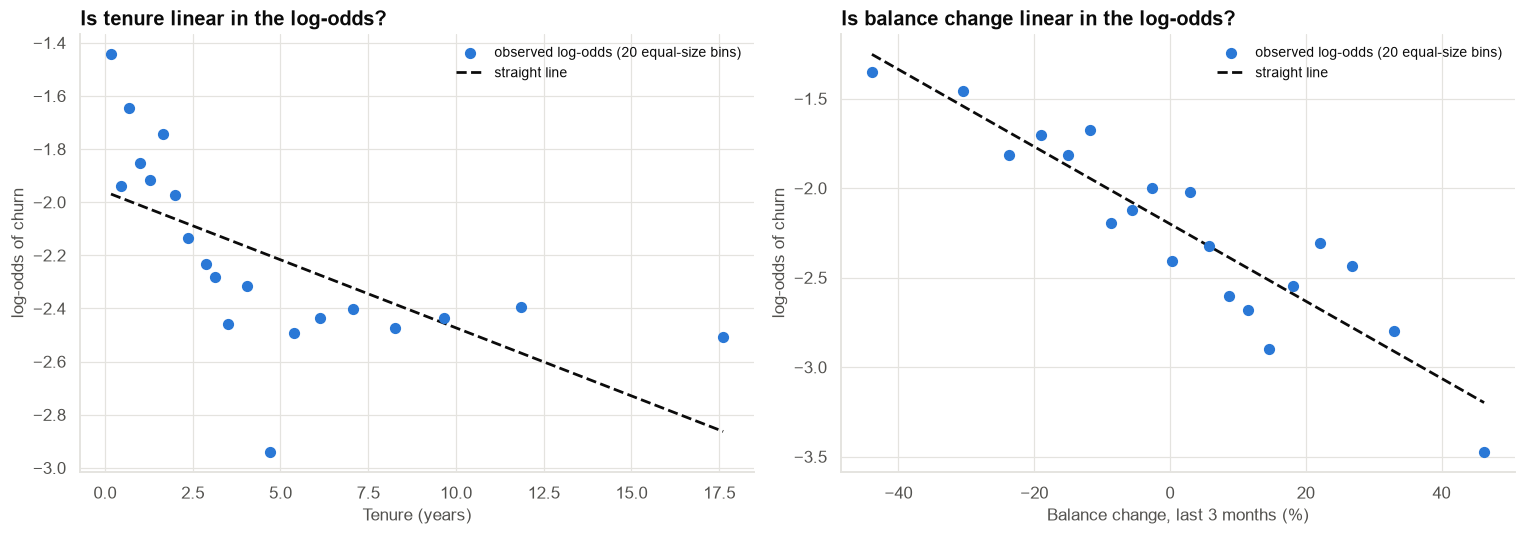

In [11]:
def binned_logit(df, col, bins):
    g = df.groupby(pd.qcut(df[col], bins, duplicates="drop"), observed=True).agg(x=(col, "mean"), y=("churned_6m", "mean"),
                                                                                 n=("churned_6m", "size"))
    g["logit"] = np.log((g["y"] + 0.5 / g["n"]) / (1 - g["y"] + 0.5 / g["n"]))
    return g

F_B = F_MAIN.replace(" + region", "")
m_lin = smf.logit(F_B, train).fit(disp=0)
m_logt = smf.logit(F_B.replace("tenure_years", "log_tenure"), train).fit(disp=0)
m_spl = smf.logit(F_B.replace("tenure_years", "bs(tenure_years, df=4, lower_bound=0, upper_bound=61)"), train).fit(disp=0)
nl = pd.DataFrame({"AIC": [m_lin.aic, m_logt.aic, m_spl.aic]},
                  index=["tenure linear", "log(1 + tenure)", "spline in tenure (4 df)"])
nl["LR test vs linear"] = [np.nan, np.nan, lr_test(m_lin, m_spl)["p_value"]]
save_table(nl, "tenure_functional_form", PATHS["tables"])
display(nl)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, lab, short in [(axes[0], "tenure_years", "Tenure (years)", "tenure"),
                            (axes[1], "balance_change_3m_pct", "Balance change, last 3 months (%)", "balance change")]:
    g = binned_logit(train, col, 20)
    ax.scatter(g["x"], g["logit"], s=40, color=PRIMARY, zorder=3, label="observed log-odds (20 equal-size bins)")
    lw = np.polyfit(g["x"], g["logit"], 1)
    xs = np.linspace(g["x"].min(), g["x"].max(), 50)
    ax.plot(xs, np.polyval(lw, xs), color=INK, ls="--", lw=1.8, label="straight line")
    ax.set(xlabel=lab, ylabel="log-odds of churn", title=f"Is {short} linear in the log-odds?")
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
save_fig(fig, "fig03_binned_logit", PATHS["figures"])
plt.show()

**Observation.** For **tenure**, the observed log-odds fall steeply over the first one to two years and then flatten:
not a straight line. A 4-df spline fits much better than a linear term (likelihood-ratio p < 0.001, lower AIC); log
tenure is in between. For **balance change**, the binned log-odds lie close to a straight line, so a linear term is
fine.

(The spline's boundary knots are fixed at 0 and 61 years, the full possible range, so that every future customer can be
scored.)

**Interpretation.** Logistic regression assumes each continuous variable is **linear in the log-odds**. The **binned
logit plot** is the standard check: group customers into bins, compute each bin's log-odds, and look for curvature.
When it bends, use a transform or a spline, and test it with a likelihood-ratio test.

## Section 11 — Does the effect of complaints depend on having a salary account? (interaction)

In [12]:
F_SPL = F_B.replace("tenure_years", "bs(tenure_years, df=4, lower_bound=0, upper_bound=61)")
m_int = smf.logit(F_SPL + " + salary_account:complaints_6m", train).fit(disp=0)
lr_int = lr_test(m_spl, m_int)
print(f"Interaction complaints × salary account: LR χ² = {lr_int['LR χ²']:.1f} on {lr_int['df']} df, p = {lr_int['p_value']:.3f}")
b = m_int.params
cov = m_int.cov_params()
rows = []
for lvl in ["1", "2+"]:
    t_main = f"complaints_6m[T.{lvl}]"
    t_int = f"salary_account:complaints_6m[T.{lvl}]"
    for sal in [0, 1]:
        est = b[t_main] + sal * b[t_int]
        se = np.sqrt(cov.loc[t_main, t_main] + sal ** 2 * cov.loc[t_int, t_int] + 2 * sal * cov.loc[t_main, t_int])
        rows.append({"complaints": lvl, "salary account": "yes" if sal else "no", "odds ratio vs no complaint": np.exp(est),
                     "ci_low": np.exp(est - 1.96 * se), "ci_high": np.exp(est + 1.96 * se)})
int_tbl = pd.DataFrame(rows).set_index(["complaints", "salary account"])
save_table(int_tbl, "complaint_odds_ratios_by_salary", PATHS["tables"])
int_tbl

Interaction complaints × salary account: LR χ² = 4.8 on 2 df, p = 0.090


odds ratio vs no complaint  ci_low  ci_high
complaints salary account                                             
1          no                                  2.3773  1.8849   2.9982
           yes                                 1.6851  1.1618   2.4443
2+         no                                  5.8207  4.2097   8.0481
           yes                                 3.5410  2.2182   5.6525

**Observation.** The point estimates suggest complaints raise the odds of churn less for salary-account customers
(odds ratio about 1.7 vs 2.4 for one complaint; 3.5 vs 5.8 for two or more), but the interaction is **not**
statistically significant (likelihood-ratio p ≈ 0.09), and the confidence intervals overlap widely.

**Interpretation.** The mechanism is plausible: salary-account customers face higher switching costs (standing
instructions, EMIs, employer paperwork). But plausible is not proven. With p ≈ 0.09 and 2 extra parameters, the data
do not justify the more complex model. **Decision: drop the interaction**, and report it as a hypothesis to check on
the next cohort (more data, or a pre-registered test).

> **Rule.** Keep an interaction when it is pre-specified **and** supported by the data, or when it materially improves
> out-of-sample prediction. A good story with weak evidence is a hypothesis, not a finding.

**Caveat: interactions on the log-odds scale vs the probability scale.** An interaction in a logistic model is
multiplicative on the odds. On the probability scale, effects differ by group even **without** an interaction term
(because baseline risks differ). Always show the result as predicted probabilities (next section) before telling a
story about "who is more affected".

The final model: **main effects + spline in tenure**, without region and without the interaction.

## Section 12 — Effects in plain terms: average marginal effects

In [13]:
m_final = m_spl
F_FINAL = F_SPL
ci = m_final.conf_int()
or_tbl = pd.DataFrame({"odds ratio": np.exp(m_final.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                       "p_value": m_final.pvalues})
or_tbl = or_tbl[~or_tbl.index.str.contains("bs\\(|Intercept")]
save_table(or_tbl, "final_odds_ratios", PATHS["tables"])
display(or_tbl)

def ame(model, df, var, delta=None, levels=None):
    # Average marginal effect: average change in predicted probability across customers.
    if levels is not None:
        a, b_ = df.copy(), df.copy()
        a[var], b_[var] = levels[0], levels[1]
        if isinstance(df[var].dtype, pd.CategoricalDtype):
            a[var] = pd.Categorical(a[var], categories=df[var].cat.categories)
            b_[var] = pd.Categorical(b_[var], categories=df[var].cat.categories)
        return (model.predict(b_) - model.predict(a)).mean()
    a, b_ = df.copy(), df.copy()
    b_[var] = b_[var] + delta
    return (model.predict(b_) - model.predict(a)).mean()

ame_rows = {
    "1 complaint (vs none)": ame(m_final, train, "complaints_6m", levels=("0", "1")),
    "2+ complaints (vs none)": ame(m_final, train, "complaints_6m", levels=("0", "2+")),
    "salary account (yes vs no)": ame(m_final, train, "salary_account", levels=(0, 1)),
    "one more product": ame(m_final, train, "num_products", delta=1),
    "credit card (yes vs no)": ame(m_final, train, "has_credit_card", levels=(0, 1)),
    "5 more logins per month": ame(m_final, train, "digital_logins_per_month", delta=5),
    "balance 10 pts lower (3-month change)": ame(m_final, train, "balance_change_3m_pct", delta=-10),
    "10 years older": ame(m_final, train, "age", delta=10),
    "tenure 1 year → 5 years": ame(m_final, train, "tenure_years", levels=(1.0, 5.0)),
}
boot = {k: [] for k in ame_rows}
for _ in range(200):
    s = train.loc[rng.choice(train.index, len(train), replace=True)]
    mb = smf.logit(F_FINAL, s).fit(disp=0)
    boot["1 complaint (vs none)"].append(ame(mb, s, "complaints_6m", levels=("0", "1")))
    boot["2+ complaints (vs none)"].append(ame(mb, s, "complaints_6m", levels=("0", "2+")))
    boot["salary account (yes vs no)"].append(ame(mb, s, "salary_account", levels=(0, 1)))
    boot["one more product"].append(ame(mb, s, "num_products", delta=1))
    boot["credit card (yes vs no)"].append(ame(mb, s, "has_credit_card", levels=(0, 1)))
    boot["5 more logins per month"].append(ame(mb, s, "digital_logins_per_month", delta=5))
    boot["balance 10 pts lower (3-month change)"].append(ame(mb, s, "balance_change_3m_pct", delta=-10))
    boot["10 years older"].append(ame(mb, s, "age", delta=10))
    boot["tenure 1 year → 5 years"].append(ame(mb, s, "tenure_years", levels=(1.0, 5.0)))
ame_tbl = pd.DataFrame({"AME (pp)": {k: 100 * v for k, v in ame_rows.items()},
                        "ci_low (pp)": {k: 100 * np.percentile(v, 2.5) for k, v in boot.items()},
                        "ci_high (pp)": {k: 100 * np.percentile(v, 97.5) for k, v in boot.items()}})
save_table(ame_tbl, "average_marginal_effects", PATHS["tables"])
display(ame_tbl)
raw_rd = {lvl: cust.loc[cust["complaints_6m"] == lvl, "churned_6m"].mean() - p0 for lvl in ["1", "2+"]}
ncol = pd.DataFrame({"raw risk difference (pp)": [100 * raw_rd["1"], 100 * raw_rd["2+"]],
                     "adjusted AME (pp)": [ame_tbl.loc["1 complaint (vs none)", "AME (pp)"], ame_tbl.loc["2+ complaints (vs none)", "AME (pp)"]],
                     "raw odds ratio": [(p0 + raw_rd[l]) / (1 - p0 - raw_rd[l]) / (p0 / (1 - p0)) for l in ["1", "2+"]],
                     "adjusted odds ratio": [np.exp(m_final.params["complaints_6m[T.1]"]), np.exp(m_final.params["complaints_6m[T.2+]"])]},
                    index=["1 complaint", "2+ complaints"])
save_table(ncol, "raw_vs_adjusted_complaints", PATHS["tables"])
print("Raw vs adjusted effect of complaints:")
display(ncol)
print("Are complaints related to the other drivers? Mean by complaint group:")
cust.groupby("complaints_6m", observed=True)[["tenure_years", "num_products", "salary_account", "digital_logins_per_month",
                                               "balance_change_3m_pct"]].mean()

,odds ratio,ci_low,ci_high,p_value
complaints_6m[T.1],2.1497,1.7672,2.6150,0.0000
complaints_6m[T.2+],4.9270,3.7879,6.4088,0.0000
segment[T.Affluent],0.9443,0.7908,1.1275,0.5263
segment[T.Privileged],0.7458,0.5017,1.1087,0.1472
age,0.9867,0.9799,0.9935,0.0001
num_products,0.6906,0.6315,0.7552,0.0000
salary_account,0.3820,0.3264,0.4469,0.0000
has_credit_card,0.7862,0.6712,0.9208,0.0029
digital_logins_per_month,0.9513,0.9287,0.9745,0.0000
balance_change_3m_pct,0.9775,0.9742,0.9807,0.0000


,AME (pp),ci_low (pp),ci_high (pp)
1 complaint (vs none),7.5811,5.5715,10.1495
2+ complaints (vs none),20.2241,15.5245,24.3765
salary account (yes vs no),-7.7647,-8.9100,-6.6716
one more product,-2.7858,-3.3250,-2.2032
credit card (yes vs no),-1.9950,-3.2273,-0.8332
5 more logins per month,-1.9563,-2.7809,-1.0651
balance 10 pts lower (3-month change),2.0931,1.7816,2.3625
10 years older,-1.0933,-1.6177,-0.5747
tenure 1 year → 5 years,-6.0924,-7.3599,-4.5707


Raw vs adjusted effect of complaints:


,raw risk difference (pp),adjusted AME (pp),raw odds ratio,adjusted odds ratio
1 complaint,7.9978,7.5811,2.0945,2.1497
2+ complaints,19.8822,20.2241,4.1743,4.9270


Are complaints related to the other drivers? Mean by complaint group:


,tenure_years,num_products,salary_account,digital_logins_per_month,balance_change_3m_pct
complaints_6m,,,,,
0,4.6003,1.9236,0.4479,8.9462,1.5050
1,4.7092,1.9376,0.4543,9.0869,1.4988
2+,4.5372,1.9023,0.4437,8.7516,2.3977


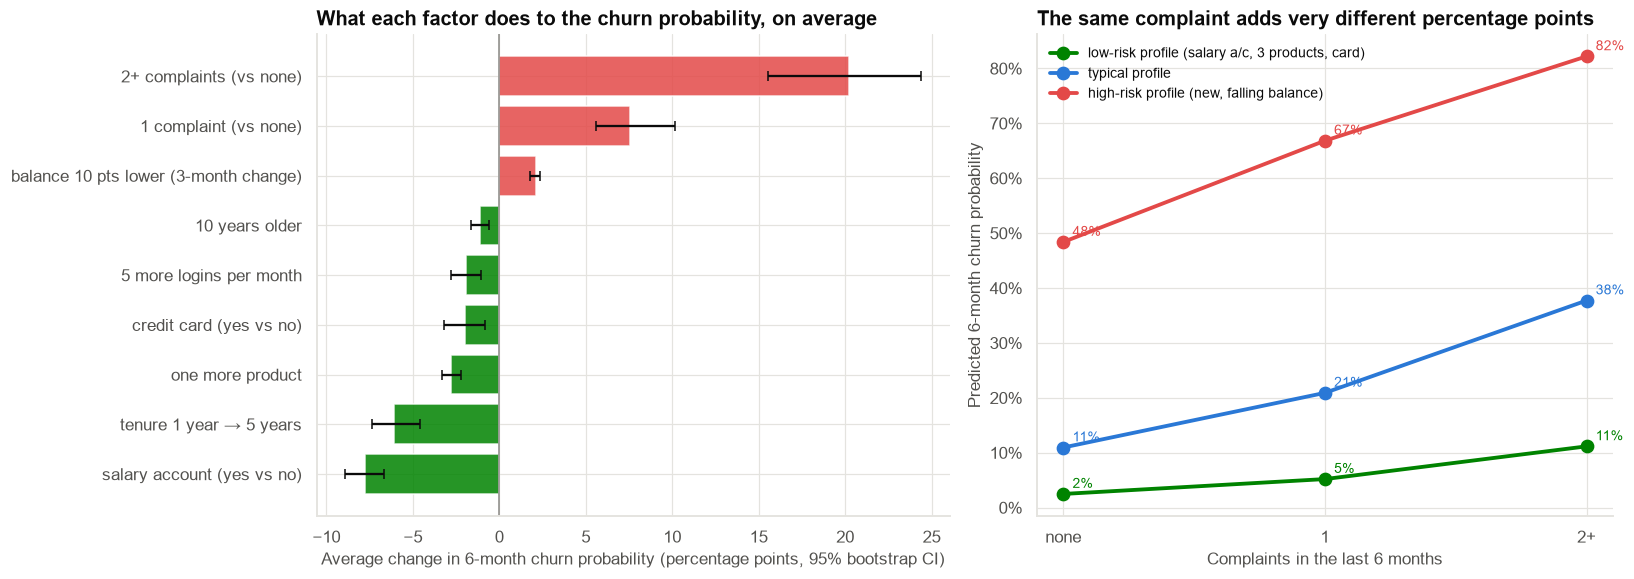

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
order = ame_tbl.sort_values("AME (pp)").index
cols = [COLORS["red"] if v > 0 else COLORS["green"] for v in ame_tbl.loc[order, "AME (pp)"]]
ax.barh(order, ame_tbl.loc[order, "AME (pp)"], color=cols, alpha=0.85)
ax.errorbar(ame_tbl.loc[order, "AME (pp)"], np.arange(len(order)),
            xerr=[ame_tbl.loc[order, "AME (pp)"] - ame_tbl.loc[order, "ci_low (pp)"],
                  ame_tbl.loc[order, "ci_high (pp)"] - ame_tbl.loc[order, "AME (pp)"]], fmt="none", color=INK, capsize=3)
ax.axvline(0, color=INK_MUTED, lw=1)
ax.set(xlabel="Average change in 6-month churn probability (percentage points, 95% bootstrap CI)",
       title="What each factor does to the churn probability, on average")

ax = axes[1]
profiles = {"low-risk profile (salary a/c, 3 products, card)": dict(salary_account=1, num_products=3, has_credit_card=1),
            "typical profile": dict(salary_account=0, num_products=2, has_credit_card=0),
            "high-risk profile (new, falling balance)": dict(salary_account=0, num_products=1, has_credit_card=0)}
for (lab, prof), col in zip(profiles.items(), [COLORS["green"], PRIMARY, COLORS["red"]]):
    base = dict(age=35, tenure_years=4.0, digital_logins_per_month=6, balance_change_3m_pct=0.0, segment="Mass")
    if "high" in lab:
        base.update(tenure_years=0.5, balance_change_3m_pct=-30.0, digital_logins_per_month=2)
    rowsp = pd.DataFrame([{**base, **prof, "complaints_6m": c} for c in ["0", "1", "2+"]])
    rowsp["complaints_6m"] = pd.Categorical(rowsp["complaints_6m"], categories=["0", "1", "2+"])
    rowsp["segment"] = pd.Categorical(rowsp["segment"], categories=train["segment"].cat.categories)
    pr = m_final.predict(rowsp)
    ax.plot(["none", "1", "2+"], pr, marker="o", ms=8, lw=2.5, color=col, label=lab)
    for x_, y_ in zip(["none", "1", "2+"], pr):
        ax.annotate(f"{y_:.0%}", (x_, y_), xytext=(6, 4), textcoords="offset points", fontsize=9, color=col)
ax.yaxis.set_major_formatter(pctfmt)
ax.set(xlabel="Complaints in the last 6 months", ylabel="Predicted 6-month churn probability",
       title="The same complaint adds very different percentage points")
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
save_fig(fig, "fig04_marginal_effects", PATHS["figures"])
plt.show()

**Observation.** On average, one complaint adds about **7–8 percentage points** to the 6-month churn probability and
two or more add about **20 points**. A salary account lowers churn by about 8 points, each extra product by about 3, a
credit card and 5 more logins a month by about 2 each (logins matter once age is held fixed, although they looked flat
on their own in Section 6); a 10-point fall in balance adds about 2 points; going from 1 to
5 years of tenure lowers churn by about 6 points. The right panel shows that **the same complaint** moves a low-risk
customer by a few points but a high-risk customer by much more.

**Interpretation.**
- An **odds ratio** is a constant multiplier on the odds; the **percentage-point** effect depends on the customer's
  starting risk. Business audiences think in percentage points, so report **average marginal effects** (AME: the
  change in predicted probability, averaged over the real customers).

### 12.1 A trap: odds ratios change when you add variables, even without confounding

Compare the raw and adjusted effects of complaints (tables above). In **percentage points**, the adjusted effect is
almost the same as the raw difference. In **odds ratios**, the adjusted effect of 2+ complaints is **larger** (about
4.9 vs 4.2). Yet complaints are essentially unrelated to the other drivers (the group means are almost identical), so
this is **not** confounding.

It is **non-collapsibility**: an odds ratio conditional on other predictors of the outcome is further from 1 than the
overall odds ratio, even when those predictors are unrelated to the exposure. Risk differences and risk ratios do not
behave this way.

> **Consequence.** In logistic regression, a coefficient that changes when you add a variable is **not**, by itself,
> evidence of confounding (unlike linear regression, Case 08). Compare **marginal effects** in percentage points, or
> check whether the added variable is related to the exposure.

**Caveat.** These are associations. "One more product lowers churn by X points" does not mean that cross-selling a
product **causes** that drop: customers who choose more products may already be more committed (Case 21).

## Section 13 — Can we trust the probabilities? Discrimination and calibration

,value
AUC (test),0.7517
AUC 95% CI low,0.7215
AUC 95% CI high,0.7810
Brier score,0.0834
Brier score of 'everyone = base rate',0.0940
Brier skill score,0.1122
Hosmer-Lemeshow χ² (8 df),9.6161
Hosmer-Lemeshow p,0.2930
mean predicted churn,0.1086
actual churn rate,0.1050


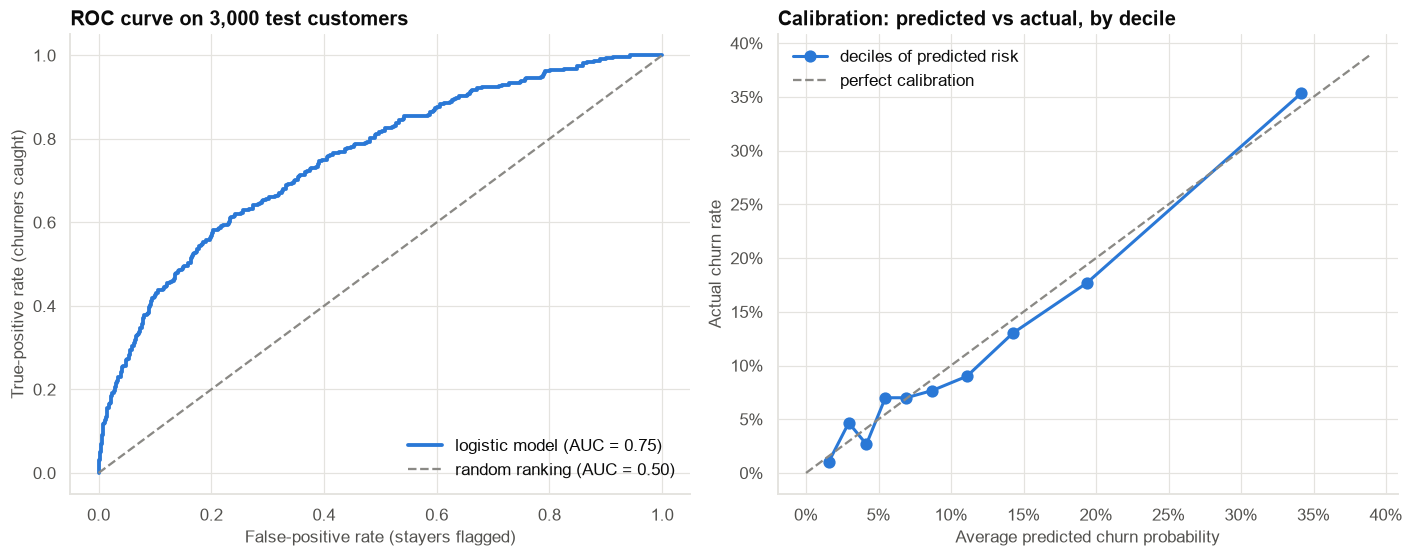

In [15]:
p_test = m_final.predict(test)
y_test = test["churned_6m"]
auc = roc_auc_score(y_test, p_test)
auc_boot = []
for _ in range(1000):
    i = rng.integers(0, len(test), len(test))
    if y_test.iloc[i].nunique() == 2:
        auc_boot.append(roc_auc_score(y_test.iloc[i], p_test.iloc[i]))
brier = brier_score_loss(y_test, p_test)
brier_ref = brier_score_loss(y_test, np.full(len(test), train["churned_6m"].mean()))
dec = pd.qcut(p_test, 10, labels=False)
cal = pd.DataFrame({"p": p_test, "y": y_test, "d": dec}).groupby("d").agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
hl = (((cal["obs"] - cal["pred"]) * cal["n"]) ** 2 / (cal["n"] * cal["pred"] * (1 - cal["pred"]))).sum()
hl_p = stats.chi2.sf(hl, 8)
quality = pd.DataFrame({"value": [auc, np.percentile(auc_boot, 2.5), np.percentile(auc_boot, 97.5), brier, brier_ref,
                                  1 - brier / brier_ref, hl, hl_p, p_test.mean(), y_test.mean()]},
                       index=["AUC (test)", "AUC 95% CI low", "AUC 95% CI high", "Brier score", "Brier score of 'everyone = base rate'",
                              "Brier skill score", "Hosmer-Lemeshow χ² (8 df)", "Hosmer-Lemeshow p", "mean predicted churn", "actual churn rate"])
save_table(quality, "model_quality_test", PATHS["tables"])
display(quality)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, color=PRIMARY, lw=2.5, label=f"logistic model (AUC = {auc:.2f})")
axes[0].plot([0, 1], [0, 1], color=INK_MUTED, ls="--", label="random ranking (AUC = 0.50)")
axes[0].set(xlabel="False-positive rate (stayers flagged)", ylabel="True-positive rate (churners caught)",
            title="ROC curve on 3,000 test customers")
axes[0].legend(frameon=False, loc="lower right")
axes[1].plot(cal["pred"], cal["obs"], "o-", color=PRIMARY, lw=2, ms=7, label="deciles of predicted risk")
lim = max(cal["pred"].max(), cal["obs"].max()) * 1.1
axes[1].plot([0, lim], [0, lim], color=INK_MUTED, ls="--", label="perfect calibration")
axes[1].xaxis.set_major_formatter(pctfmt); axes[1].yaxis.set_major_formatter(pctfmt)
axes[1].set(xlabel="Average predicted churn probability", ylabel="Actual churn rate",
            title="Calibration: predicted vs actual, by decile")
axes[1].legend(frameon=False, loc="upper left")
fig.tight_layout()
save_fig(fig, "fig05_roc_calibration", PATHS["figures"])
plt.show()

**Observation.** On 3,000 customers the model never saw, the AUC is about 0.75 (95% CI 0.72–0.78): picking one churner and one stayer at
random, the model ranks the churner higher about three times out of four. Predicted probabilities line up with actual
churn rates across deciles (Hosmer-Lemeshow does not reject), and the average prediction matches the actual rate.

**Interpretation.**
- **Discrimination** (AUC): can the model **rank** customers? 0.5 = random, 1 = perfect; 0.7–0.8 is typical and useful
  for behavioural outcomes.
- **Calibration**: when the model says 20%, do about 20% churn? This matters whenever probabilities feed a **money**
  decision, as they do here.
- They are different properties: a model can rank well and be badly calibrated (common after resampling, Case 12),
  or be calibrated and rank poorly.

## Section 14 — Whom should the retention team call?

**Expected value of calling a customer** with churn probability p:

  EV = p × (offer success rate) × (value of a retained customer) − (offer cost)
     = p × 0.35 × ₹12,000 − ₹600

Calling pays off when p > ₹600 / (0.35 × ₹12,000) ≈ **14.3%**. The default "p > 50%" threshold would ignore most of
the profitable customers.

In [16]:
# Out-of-fold predictions for every modelled customer (each customer scored by a model that did not see them).
oof = pd.Series(np.nan, index=model_df.index)
skf = StratifiedKFold(5, shuffle=True, random_state=11)
for tr, te in skf.split(model_df, model_df["churned_6m"]):
    mm = smf.logit(F_FINAL, model_df.iloc[tr]).fit(disp=0)
    oof.iloc[te] = mm.predict(model_df.iloc[te]).to_numpy()
model_df["p_churn"] = oof
p_star = OFFER_COST / (OFFER_SUCCESS * CLV)
model_df["ev_call"] = model_df["p_churn"] * OFFER_SUCCESS * CLV - OFFER_COST

ranked = model_df.sort_values("p_churn", ascending=False)
strategies = {}
def summarise(sel, name):
    tp = sel["churned_6m"].sum()
    strategies[name] = {"customers called": len(sel), "lowest p called": sel["p_churn"].min() if len(sel) else np.nan,
                        "churners reached": tp, "precision (churners / called)": tp / max(len(sel), 1),
                        "recall (share of all churners)": tp / model_df["churned_6m"].sum(),
                        "expected net value (₹, model)": sel["ev_call"].sum(),
                        "realised net value (₹)": tp * OFFER_SUCCESS * CLV - len(sel) * OFFER_COST}
summarise(ranked[ranked["p_churn"] > 0.5], "p > 50% (default threshold)")
summarise(ranked[ranked["p_churn"] > p_star], f"p > {p_star:.1%} (break-even, no capacity limit)")
summarise(ranked.head(CAPACITY), f"top {CAPACITY:,} by probability (capacity)")
summarise(model_df.sample(CAPACITY, random_state=1), f"{CAPACITY:,} random customers")
strat = pd.DataFrame(strategies).T
save_table(strat, "call_strategies", PATHS["tables"])
strat

,customers called,lowest p called,churners reached,precision (churners / called),recall (share of all churners),"expected net value (₹, model)",realised net value (₹)
p > 50% (default threshold),86.0000,0.5018,52.0000,0.6047,0.0414,"157,542.3560","166,800.0000"
"p > 14.3% (break-even, no capacity limit)","2,807.0000",0.1429,684.0000,0.2437,0.5450,"1,189,265.0111","1,188,600.0000"
"top 1,000 by probability (capacity)","1,000.0000",0.2459,353.0000,0.3530,0.2813,"864,061.4846","882,600.0000"
"1,000 random customers","1,000.0000",0.0009,118.0000,0.1180,0.0940,"-147,780.4280","-104,400.0000"


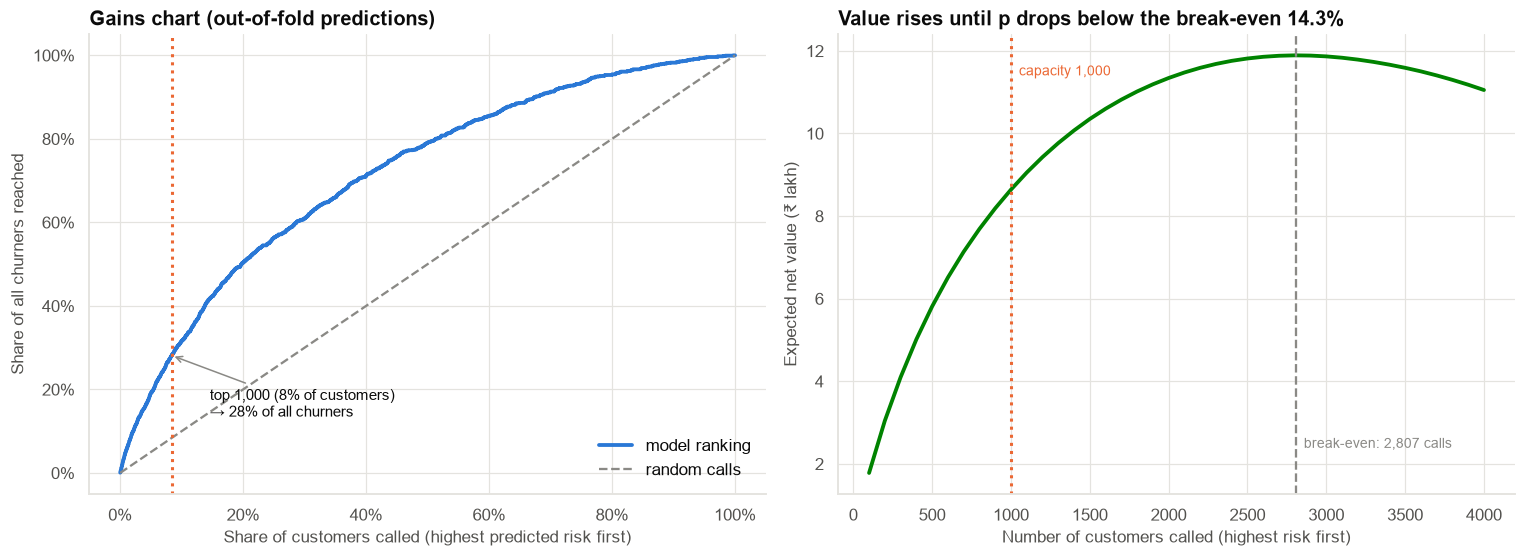

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
cum = ranked["churned_6m"].cumsum() / ranked["churned_6m"].sum()
share = np.arange(1, len(ranked) + 1) / len(ranked)
ax.plot(share, cum, color=PRIMARY, lw=2.5, label="model ranking")
ax.plot([0, 1], [0, 1], color=INK_MUTED, ls="--", label="random calls")
k = CAPACITY / len(ranked)
ax.axvline(k, color=HIGHLIGHT, ls=":", lw=2)
ax.annotate(f"top {CAPACITY:,} ({k:.0%} of customers)\n→ {cum.iloc[CAPACITY - 1]:.0%} of all churners",
            (k, cum.iloc[CAPACITY - 1]), xytext=(25, -40), textcoords="offset points", fontsize=10,
            arrowprops=dict(arrowstyle="->", color=INK_MUTED))
ax.xaxis.set_major_formatter(pctfmt); ax.yaxis.set_major_formatter(pctfmt)
ax.set(xlabel="Share of customers called (highest predicted risk first)", ylabel="Share of all churners reached",
       title="Gains chart (out-of-fold predictions)")
ax.legend(frameon=False, loc="lower right")
ax = axes[1]
n_calls = np.arange(100, 4001, 100)
cum_ev = [ranked["ev_call"].head(n).sum() / 1e5 for n in n_calls]
ax.plot(n_calls, cum_ev, color=COLORS["green"], lw=2.5)
n_be = int((ranked["p_churn"] > p_star).sum())
ax.axvline(n_be, color=INK_MUTED, ls="--", lw=1.5)
ax.axvline(CAPACITY, color=HIGHLIGHT, ls=":", lw=2)
ax.text(n_be, ax.get_ylim()[0] + 0.1 * np.ptp(ax.get_ylim()), f"  break-even: {n_be:,} calls", fontsize=9, color=INK_MUTED)
ax.text(CAPACITY, ax.get_ylim()[1] * 0.92, f"  capacity {CAPACITY:,}", fontsize=9, color=HIGHLIGHT)
ax.set(xlabel="Number of customers called (highest risk first)", ylabel="Expected net value (₹ lakh)",
       title="Value rises until p drops below the break-even 14.3%")
fig.tight_layout()
save_fig(fig, "fig06_gains_and_value", PATHS["figures"])
plt.show()

**Observation.**
- With the default **p > 50%** rule, the team would call only 86 customers and reach 4% of churners.
- **2,807** customers have a churn probability above the break-even 14.3%; calling all of them would maximise value
  (≈ ₹12 lakh net), but capacity is 1,000.
- Calling the **top 1,000** by predicted probability (all above 25%) reaches **353 churners, 28% of all churners**,
  while calling 8% of customers. Precision is 35%, about 3.4 times the base rate, and the net value is about
  **₹8.8 lakh**. 1,000 random calls would **lose** about ₹1 lakh.
- The model's expected value and the realised value agree closely, another sign of good calibration.

**Interpretation.** Thresholds are a **business** decision, not a statistical one. The right cut-off comes from the
costs and benefits (and the capacity), not from 0.5. Because the decision uses the probabilities in ₹, **calibration**
matters as much as ranking.

**Caveat: risk ≠ persuadability.** The model finds customers likely to **leave**, not customers whom a call would
**keep**. The 35% success rate is an assumption; some high-risk customers will leave whatever we do, and some calls may
remind satisfied customers to shop around. The right next step is a **randomised test** of the offer (Case 04) and,
later, an **uplift** model (Case 21).

## Section 15 — Model checks

In [18]:
Xv = train[["age", "tenure_years", "num_products", "salary_account", "has_credit_card", "digital_logins_per_month",
            "balance_change_3m_pct"]].assign(const=1.0)
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1] - 1)], index=Xv.columns[:-1])
print("VIF of numeric predictors:", vif.round(2).to_dict())
stab = pd.DataFrame({"train OR": np.exp(m_final.params), "refit on test OR": np.exp(smf.logit(F_FINAL, test).fit(disp=0).params)})
stab = stab[~stab.index.str.contains("bs\\(|Intercept|segment")]
display(stab)

VIF of numeric predictors: {'age': 1.21, 'tenure_years': 1.04, 'num_products': 1.03, 'salary_account': 1.01, 'has_credit_card': 1.01, 'digital_logins_per_month': 1.2, 'balance_change_3m_pct': 1.0}


,train OR,refit on test OR
complaints_6m[T.1],2.1497,2.8422
complaints_6m[T.2+],4.9270,4.3323
age,0.9867,0.9789
num_products,0.6906,0.6827
salary_account,0.3820,0.3231
has_credit_card,0.7862,0.8069
digital_logins_per_month,0.9513,0.9277
balance_change_3m_pct,0.9775,0.9781


**Observation.** VIFs are low (no multicollinearity problem, Case 09). Refitting the model on the 3,000 test
customers gives odds ratios in the same direction and mostly of similar size; the one-complaint odds ratio is noisier
(about 2.1 in training vs 2.8 in the smaller test sample), as expected with fewer events.

## Section 16 — Results

In [19]:
o = or_tbl["odds ratio"]
summary = pd.DataFrame({"Value": [
    f"{base_rate:.1%} over 6 months ({cust['churned_6m'].sum():,} of {len(cust):,})",
    f"raw risk ratio {two.loc['risk ratio', 'value']:.1f}, odds ratio {two.loc['odds ratio (from the 2×2 table)', 'value']:.1f} (any complaint); RR {g2 / p0:.1f} for 2+",
    f"AME {ame_tbl.loc['1 complaint (vs none)', 'AME (pp)']:+.1f} pp (1), {ame_tbl.loc['2+ complaints (vs none)', 'AME (pp)']:+.1f} pp (2+)",
    f"salary account {ame_tbl.loc['salary account (yes vs no)', 'AME (pp)']:+.1f} pp; one more product {ame_tbl.loc['one more product', 'AME (pp)']:+.1f} pp; "
    f"balance −10 pts {ame_tbl.loc['balance 10 pts lower (3-month change)', 'AME (pp)']:+.1f} pp",
    f"spline LR p = {fmt_p(nl.loc['spline in tenure (4 df)', 'LR test vs linear'])}; tenure 1 → 5 yrs {ame_tbl.loc['tenure 1 year → 5 years', 'AME (pp)']:+.1f} pp",
    f"LR p = {lr_int['p_value']:.3f}: not significant, dropped",
    f"region LR p = {blocks.loc['region (4 df)', 'p_value']:.2f}; segment LR p = {blocks.loc['segment (2 df)', 'p_value']:.2f}",
    f"AUC {auc:.2f} ({np.percentile(auc_boot, 2.5):.2f}–{np.percentile(auc_boot, 97.5):.2f}); Hosmer-Lemeshow p = {hl_p:.2f}",
    f"break-even p = {p_star:.1%}; top {CAPACITY:,}: {strat.iloc[2]['churners reached']:.0f} churners reached, "
    f"realised net value {fmt_money(strat.iloc[2]['realised net value (₹)'])}",
]}, index=["Churn rate", "Complaints (raw)", "Complaints (adjusted)", "Other drivers", "Tenure (non-linear)",
           "Complaints × salary account", "Not drivers", "Model quality (test)", "Call list"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Churn rate,"10.5% over 6 months (1,255 of 12,000)"
Complaints (raw),"raw risk ratio 2.3, odds ratio 2.6 (any compla..."
Complaints (adjusted),"AME +7.6 pp (1), +20.2 pp (2+)"
Other drivers,salary account -7.8 pp; one more product -2.8 ...
Tenure (non-linear),spline LR p = < 0.001; tenure 1 → 5 yrs -6.1 pp
Complaints × salary account,"LR p = 0.090: not significant, dropped"
Not drivers,region LR p = 0.97; segment LR p = 0.26
Model quality (test),AUC 0.75 (0.72–0.78); Hosmer-Lemeshow p = 0.29
Call list,"break-even p = 14.3%; top 1,000: 353 churners ..."


## Section 17 — Interpretation

- **Drivers.** Complaints, falling balances, low digital engagement and being new raise churn; salary accounts, more
  products and credit cards lower it. Region and segment do not matter once these are known.
- **"Three times more likely."** True for 2+ complaints, as a raw risk ratio (≈ 3.3); one complaint is about 1.9×.
  The adjusted percentage-point effects (+8 and +20 points) match the raw differences, because complaints are not
  confounded with the other drivers here. The adjusted **odds** ratios are larger, purely from non-collapsibility.
- **Odds ratios vs percentage points.** Odds ratios are constant multipliers; the percentage-point effect depends on
  the customer's baseline risk. Report AMEs to business audiences.
- **Model quality.** Useful ranking (AUC ≈ 0.75) and well-calibrated probabilities, which matters because they drive
  a ₹ decision.

## Section 18 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Customers with two or more complaints churned at about 3 times the rate of customers with none." | "Any complaint makes a customer three times more likely to leave." (One complaint: about 1.9×.) |
| "Holding the other factors fixed, the odds of churn are about X times higher after a complaint." | "The probability is X times higher." (That is a risk ratio, not an odds ratio.) |
| "On average, a complaint is associated with about N percentage points higher churn probability." | "Resolving complaints will cut churn by N points." (Not tested causally.) |
| "The top 1,000 predicted include about 28% of all churners." | "Calling them will retain 35% of them." (An assumption until tested.) |

## Section 19 — Business interpretation

- **Retention calls:** score customers monthly; call the top 1,000 by predicted probability (all above the 14.3%
  break-even). Expected value is clearly positive; random or "p > 50%" calling is not.
- **Complaints:** two or more complaints add about 20 points of churn risk: escalate repeat complainants. Whether
  salary-account customers are less affected is suggestive but unproven (p ≈ 0.09).
- **Engagement:** customers in their first year and customers with falling balances are the early-warning groups.
- **NRI customers:** low risk by rule; excluded from the model.

## Section 20 — Limitations

- Associations, not causes: the model tells you **who** is at risk, not what will **change** their behaviour.
- The offer success rate (35%) and customer value (₹12,000) are assumptions; the threshold moves with them.
- One 6-month cohort; the model should be validated out of time (Case 13).
- Synthetic data.

## Section 21 — Final recommendation

> **Use the logistic churn model to rank customers each month and call the top 1,000** (all above the 14.3% break-even
> probability). Report effects to the business as percentage points, not odds ratios. **Run the retention offer as a
> randomised test** for the first two months to measure its real success rate before scaling.

## Section 22 — What would I do next?

1. **A/B test the offer** among high-risk customers (Case 04 design) to measure its true retention effect.
2. Build an **uplift model** once test data exist: target customers whose behaviour the call changes (Case 21).
3. Validate **out of time** on the next cohort; monitor calibration monthly.
4. Compare with a gradient-boosting model using the Case 13 playbook, and keep logistic unless the gain is worth it.
5. Continue to **Case 12** (fraud: when the positive class is very rare, accuracy and AUC can mislead).